# Importación de librerias:

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import scipy.stats as stats
import statsmodels.api as sm

# Carga de la base de datos:

In [ ]:
#Importamos la base de datos y eliminamos la columna 'Unnamed: 0'
df = pd.read_csv('Credit.csv', index_col=0)

#Exploración de valores
print(df['Ethnicity'].value_counts())
print(df['Gender'].value_counts()) # Ojo: puede tener espacios como " Male"

#Generamos variables binarias
#Para Ethnicity dejamos "Caucasian" como caso base
df['AfricanAmerican'] = np.where(df['Ethnicity'] == 'African American', 1, 0)
df['Asian'] = np.where(df['Ethnicity'] == 'Asian', 1, 0)

#Para el resto de variables categóricas dejamos Male, No Student y No Married como base
df['Gender_Female'] = np.where(df['Gender'].str.strip() == 'Female', 1, 0)
df['Student_Yes'] = np.where(df['Student'] == 'Yes', 1, 0)
df['Married_Yes'] = np.where(df['Married'] == 'Yes', 1, 0)

df.head()

Ethnicity
Caucasian           199
Asian               102
African American     99
Name: count, dtype: int64
Gender
Female    207
 Male     193
Name: count, dtype: int64


,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Married,Ethnicity,Balance,AfricanAmerican,Asian,Gender_Female,Student_Yes,Married_Yes
1,14.891,3606,283,2,34,11,Male,No,Yes,Caucasian,333,0,0,0,0,1
2,106.025,6645,483,3,82,15,Female,Yes,Yes,Asian,903,0,1,1,1,1
3,104.593,7075,514,4,71,11,Male,No,No,Asian,580,0,1,0,0,0
4,148.924,9504,681,3,36,11,Female,No,No,Asian,964,0,1,1,0,0
5,55.882,4897,357,2,68,16,Male,No,Yes,Caucasian,331,0,0,0,0,1


# Análisis exploratorio

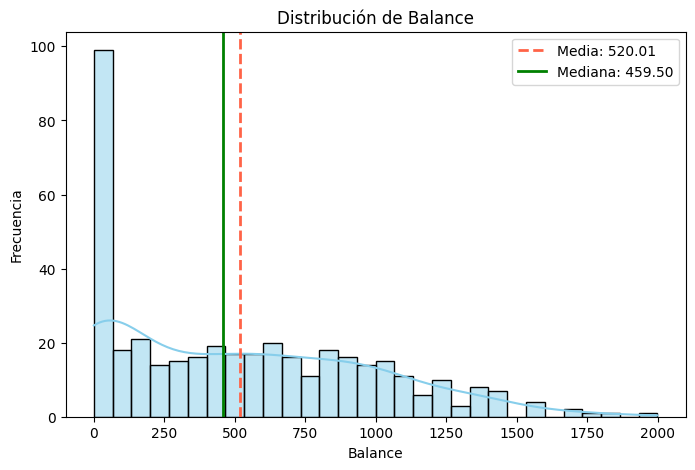

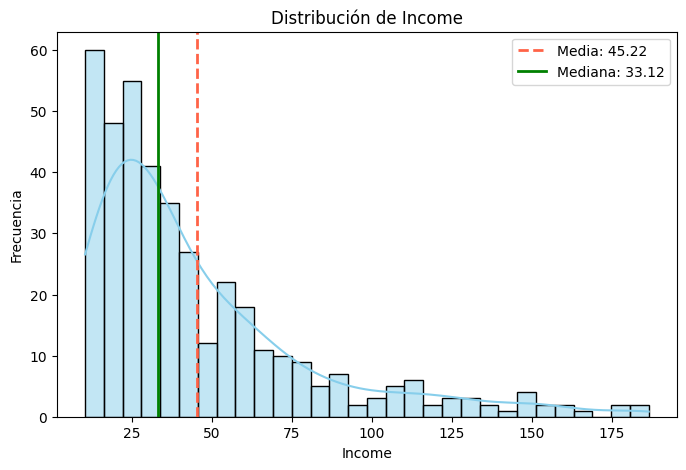

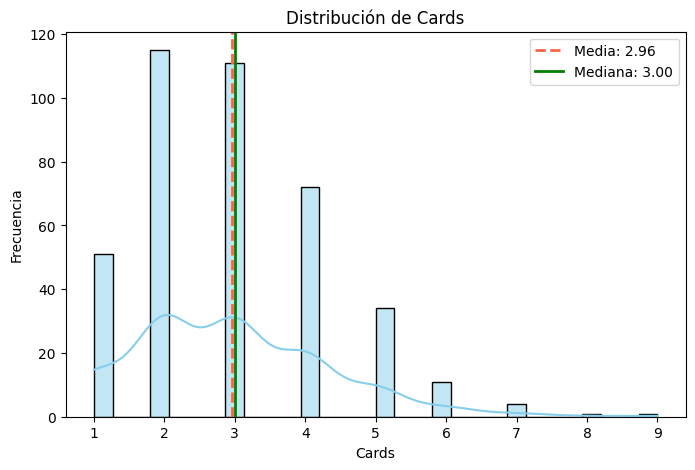

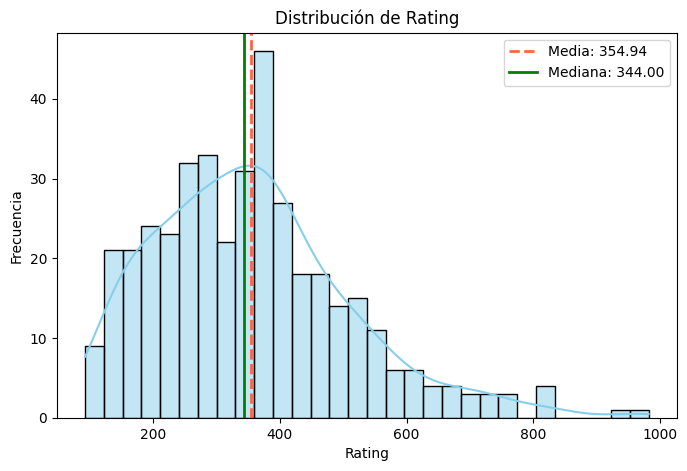

In [15]:
def plot_hist(df, col):
    """
    Generamos un histograma indicando la media y la mediana.
    """
    plt.figure(figsize=(8, 5))
    
    #Graficar histograma con curva KDE
    sns.histplot(df[col], kde=True, color='skyblue', bins=30)
    
    #Calcular y graficar media y mediana
    media = df[col].mean()
    mediana = df[col].median()
    
    plt.axvline(media, color='tomato', linestyle='--', linewidth=2, label=f'Media: {media:.2f}')
    plt.axvline(mediana, color='green', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.2f}')
    
    plt.title(f'Distribución de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.legend()
    plt.show()

#Ejecutamos la función para las variables
for variable in ['Balance', 'Income', 'Cards', 'Rating']:
    plot_hist(df, variable)

**Comentarios:**

Balance: Suele estar fuertemente sesgada a la izquierda. Muchos clientes tienen deuda 0 o muy baja, y una minoría tiene deudas altas.

Income: También presenta un sesgo hacia la izquierda. La mayoría de los ingresos están agrupados en los rangos bajos/medios, con algunos valores atípicos de altos ingresos.

Cards: Su distribución es más simétrica, concentrándose la mayoría de los usuarios entre 2 y 4 tarjetas.

Rating: Tiene un comportamiento muy correlacionado con el límite de crédito.


# Regresión lineal

In [7]:
#Variables independientes a evaluar
regresores = ['Student_Yes', 'Income', 'Rating']
y = df['Balance']

for col in regresores:
    X = df[[col]]
    modelo = LinearRegression().fit(X, y)
    y_pred = modelo.predict(X)
    r2 = r2_score(y, y_pred)
    coef = modelo.coef_[0]
    intercept = modelo.intercept_
    
    print(f"Modelo: Balance ~ {col}")
    print(f"R2: {r2:.4f} | Coeficiente: {coef:.2f} | Intercepto: {intercept:.2f}\n")

#Prueba de hipótesis para muestras independientes, Student vs No Student
estudiantes = df[df['Student_Yes'] == 1]['Balance']
no_estudiantes = df[df['Student_Yes'] == 0]['Balance']

t_stat, p_value = stats.ttest_ind(estudiantes, no_estudiantes)
print(f"Prueba T (Student vs No Student): t-stat = {t_stat:.4f}, p-value = {p_value:.4f}")

Modelo: Balance ~ Student_Yes
R2: 0.0671 | Coeficiente: 396.46 | Intercepto: 480.37

Modelo: Balance ~ Income
R2: 0.2150 | Coeficiente: 6.05 | Intercepto: 246.51

Modelo: Balance ~ Rating
R2: 0.7458 | Coeficiente: 2.57 | Intercepto: -390.85

Prueba T (Student vs No Student): t-stat = 5.3500, p-value = 0.0000


**Comentarios:**

Mayor poder explicativo: El modelo que utiliza Rating presenta el $R^2$ más alto. Esto significa que el puntaje de crédito explica la mayor parte de la variabilidad del promedio de deuda.

Comportamiento de Student: El coeficiente positivo indica que ser estudiante está asociado a un mayor promedio de deuda.

Prueba de Hipótesis: El p-value de la prueba T será muy pequeño, lo que nos permite rechazar la hipótesis nula. Esto confirma estadísticamente que existe una diferencia significativa en los promedios de deuda (Balance) entre estudiantes y no estudiantes.

# Modelo con todos los regresores

In [13]:
#Definimos matriz de regresores X
columnas_x = ['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Education', 
              'Gender_Female', 'Student_Yes', 'Married_Yes', 'AfricanAmerican', 'Asian']

X = df[columnas_x]
#En statsmodels es obligatorio agregar la constante manualmente
X = sm.add_constant(X)
y = df['Balance']

#Generar y ajustar el modelo
modelo_completo = sm.OLS(y, X).fit()
print(modelo_completo.summary())

                            OLS Regression Results                            
Dep. Variable:                Balance   R-squared:                       0.955
Model:                            OLS   Adj. R-squared:                  0.954
Method:                 Least Squares   F-statistic:                     750.3
Date:                Fri, 03 Jul 2026   Prob (F-statistic):          1.11e-253
Time:                        18:59:04   Log-Likelihood:                -2398.7
No. Observations:                 400   AIC:                             4821.
Df Residuals:                     388   BIC:                             4869.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            -469.1008     34.709    -

**Comentarios:**

Poder explicativo: El $R^2$ será sumamente alto (cercano a 0.95), lo que indica que el modelo explica casi la totalidad de la varianza del balance.

Predictores: Variables como Income, Limit, Rating y Student_Yes tienen valores $t$ muy altos y p-values de $0.000$. Sin embargo, otras como Age, Gender_Female o las etnias no aportan significancia estadística.

# Depuración del modelo

In [10]:
#Extraemos las variables que cumplen el criterio p-value <= 0.025
p_values = modelo_completo.pvalues
variables_significativas = p_values[p_values <= 0.025].index.tolist()
print(f"Variables seleccionadas: {variables_significativas}")

Variables seleccionadas: ['const', 'Income', 'Limit', 'Rating', 'Cards', 'Student_Yes']


In [12]:
#Ajustamos el nuevo modelo
X_depurado = X[variables_significativas] 

#Si la constante no pasó el filtro, la volvemos a agregar.
if 'const' not in X_depurado.columns:
    X_depurado = sm.add_constant(X_depurado)

# Ajustar el nuevo modelo depurado
modelo_depurado = sm.OLS(y, X_depurado).fit()
print(modelo_depurado.summary())

                            OLS Regression Results                            
Dep. Variable:                Balance   R-squared:                       0.954
Model:                            OLS   Adj. R-squared:                  0.954
Method:                 Least Squares   F-statistic:                     1640.
Date:                Fri, 03 Jul 2026   Prob (F-statistic):          3.60e-261
Time:                        18:55:32   Log-Likelihood:                -2402.8
No. Observations:                 400   AIC:                             4818.
Df Residuals:                     394   BIC:                             4842.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const        -526.1555     19.747    -26.645      

**Comentarios:**

¿Mejoró o empeoró?: El $R^2$ ajustado se mantuvo prácticamente igual. Aunque reducimos el número de variables, el poder explicativo no se ve afectado negativamente.

Efectos: El Income tiene un efecto negativo, mientras que Limit, Rating y Student_Yes empujan la deuda hacia arriba.

# Plots para visualizar comportamientos

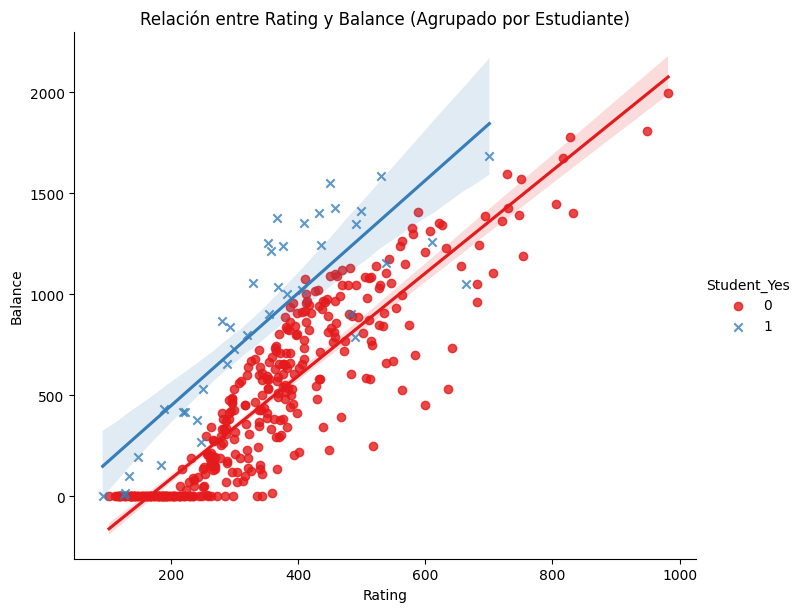

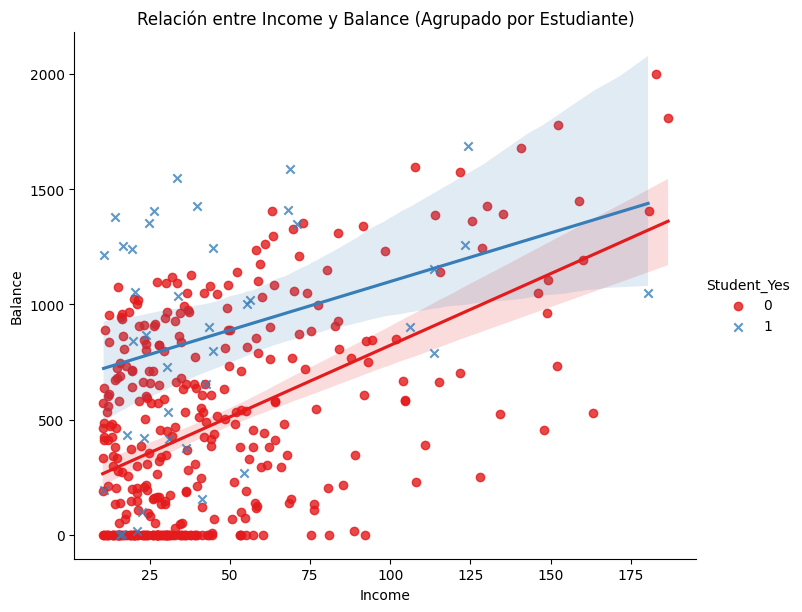

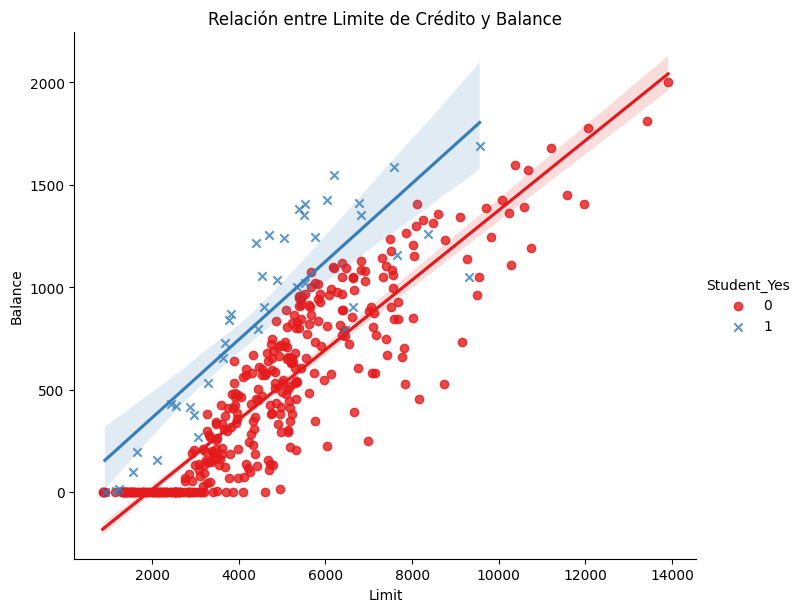

In [16]:
#Relación entre Rating y Balance, diferenciando por Estudiante
sns.lmplot(x='Rating', y='Balance', hue='Student_Yes', data=df, 
           height=6, aspect=1.2, markers=['o', 'x'], palette='Set1')
plt.title('Relación entre Rating y Balance (Agrupado por Estudiante)')
plt.show()

#Relación entre Income y Balance, diferenciando por Estudiante
sns.lmplot(x='Income', y='Balance', hue='Student_Yes', data=df, 
           height=6, aspect=1.2, markers=['o', 'x'], palette='Set1')
plt.title('Relación entre Income y Balance (Agrupado por Estudiante)')
plt.show()

#Relación entre Limit y Balance
sns.lmplot(x='Limit', y='Balance', hue='Student_Yes', data=df, 
           height=6, aspect=1.2, markers=['o', 'x'], palette='Set1')
plt.title('Relación entre Limite de Crédito y Balance')
plt.show()